In [2]:
# ============================================================
# Script purpose:
# This notebook updates Metasheet_Analysis.xlsx by filling
# Patient_Identifier and Patient_id.
#
# 1. Patient_Identifier is extracted from Collaborator_sample_id
#    Example: AUP-AL1Y-NB1 -> AL1Y
#
# 2. Clinical Barcode values from AUP_ClinicalData_20260609.NO.DA
#    are used to build a mapping between Patient_Identifier
#    and numeric patient_id.
#    Example: AUP-AQ0Z-TTP2-B -> AQ0Z -> patient_id = 1
#
# 3. Patient_id is filled in the metasheet when the extracted
#    Patient_Identifier matches the clinical Barcode-derived ID.
#
# 4. The script prints mapping summaries and reports conflicts
#    where one Patient_Identifier maps to multiple patient_id values.
# ============================================================

import re
from pathlib import Path
import pandas as pd

# ============================================================
# Input files
# ============================================================

metasheet_file = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/Metasheet_Analysis.xlsx"
)

clinical_file = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/AUP_ClinicalData_20260609.xlsx"
)

clinical_sheet = "AUP_ClinicalData_20260609.NO.DA"

# Final updated output
out_file = metasheet_file.with_name(
    "Metasheet_Analysis.with_Patient_Identifier_and_Patient_id.xlsx"
)

# If True, overwrite existing Patient_Identifier and Patient_id columns
OVERWRITE_EXISTING = True


# ============================================================
# Helper functions
# ============================================================

def is_blank(x):
    if pd.isna(x):
        return True
    s = str(x).strip()
    return s == "" or s.lower() in {"nan", "na", "none", "null"}


def clean_patient_id(x):
    """
    Clean numeric patient_id from clinical file.
    Example:
        1      -> "1"
        1.0    -> "1"
        "1.0"  -> "1"
    """
    if is_blank(x):
        return pd.NA

    s = str(x).strip()

    try:
        f = float(s)
        if f.is_integer():
            return str(int(f))
    except Exception:
        pass

    return s


def extract_aup_identifier(x):
    """
    Extract 4-character patient identifier.

    Examples:
        AUP-AQ0Z-TTP2-B  -> AQ0Z
        AUP-AQ0Z-TTM1-A  -> AQ0Z
        AUP-AMCZ-TTP1-B  -> AMCZ
        AMCZ-NB1         -> AMCZ
        AQ30-NB1         -> AQ30
        AO01-NB1         -> AO01
        AM01-NB1         -> AM01
    """
    if is_blank(x):
        return pd.NA

    s = str(x).strip().upper()

    # Pattern 1: AUP-XXXX-...
    m = re.search(r"\bAUP-([A-Z0-9]{4})(?:-|$)", s)
    if m:
        return m.group(1)

    # Pattern 2: XXXX-NB1 / XXXX-NB2 etc.
    m = re.search(r"\b([A-Z0-9]{4})-NB\d+\b", s)
    if m:
        return m.group(1)

    # Fallback: first 4-character block before a dash
    m = re.search(r"\b([A-Z0-9]{4})(?:-|$)", s)
    if m:
        return m.group(1)

    return pd.NA


# ============================================================
# 1. Read files
# ============================================================

print("Reading metasheet...")
meta = pd.read_excel(metasheet_file, sheet_name=0)

print("Reading clinical file...")
clin = pd.read_excel(clinical_file, sheet_name=clinical_sheet)

print(f"Metasheet rows: {meta.shape[0]}")
print(f"Clinical rows: {clin.shape[0]}")


# ============================================================
# 2. Check required columns
# ============================================================

required_meta_cols = [
    "Collaborator_sample_id",
    "Patient_Identifier",
    "Patient_id",
]

required_clin_cols = [
    "patient_id",
    "Barcode",
]

for col in required_meta_cols:
    if col not in meta.columns:
        raise ValueError(f"Missing column in metasheet: {col}")

for col in required_clin_cols:
    if col not in clin.columns:
        raise ValueError(f"Missing column in clinical file: {col}")


# ============================================================
# 3. Fill Patient_Identifier in metasheet
#    From Collaborator_sample_id
#    Example: AUP-AL1Y-NB1 -> AL1Y
# ============================================================

meta["Patient_Identifier_new"] = meta["Collaborator_sample_id"].apply(
    extract_aup_identifier
)

if OVERWRITE_EXISTING:
    meta["Patient_Identifier"] = meta["Patient_Identifier_new"]
else:
    mask = meta["Patient_Identifier"].apply(is_blank)
    meta.loc[mask, "Patient_Identifier"] = meta.loc[mask, "Patient_Identifier_new"]

meta = meta.drop(columns=["Patient_Identifier_new"])

print("\n========== Patient_Identifier summary ==========")
print(f"Rows with Patient_Identifier: {meta['Patient_Identifier'].notna().sum()}")
print(
    f"Unique Patient_Identifier in metasheet: "
    f"{meta['Patient_Identifier'].dropna().nunique()}"
)


# ============================================================
# 4. Build crosswalk from clinical Barcode
#    Barcode -> Patient_Identifier -> numeric patient_id
# ============================================================

clin_xwalk = clin[["patient_id", "Barcode"]].copy()

clin_xwalk["Patient_Identifier"] = clin_xwalk["Barcode"].apply(
    extract_aup_identifier
)

clin_xwalk["patient_id_clean"] = clin_xwalk["patient_id"].apply(
    clean_patient_id
)

# Keep only usable rows
clin_xwalk = clin_xwalk[
    clin_xwalk["Patient_Identifier"].notna()
    & clin_xwalk["patient_id_clean"].notna()
].copy()

print("\n========== Clinical crosswalk input summary ==========")
print(f"Clinical rows with usable Barcode + patient_id: {clin_xwalk.shape[0]}")
print(
    f"Unique Patient_Identifier from clinical Barcode: "
    f"{clin_xwalk['Patient_Identifier'].nunique()}"
)


# ============================================================
# 5. Collapse clinical crosswalk
#    If one Patient_Identifier maps to multiple patient_id values,
#    report as conflict and do not use that identifier for filling.
# ============================================================

id_to_patient_ids = (
    clin_xwalk
    .groupby("Patient_Identifier")["patient_id_clean"]
    .apply(lambda x: sorted(set(x), key=lambda y: int(y) if str(y).isdigit() else str(y)))
)

conflicts = id_to_patient_ids[id_to_patient_ids.apply(len) > 1]
valid_map_series = id_to_patient_ids[id_to_patient_ids.apply(len) == 1].apply(lambda x: x[0])
valid_map = valid_map_series.to_dict()

print("\n========== Crosswalk summary ==========")
print(f"Valid one-to-one mappings: {len(valid_map)}")
print(f"Conflicting mappings: {len(conflicts)}")

if len(conflicts) > 0:
    print("\nWARNING: These Patient_Identifier values map to multiple patient_id values.")
    print("They will NOT be used for filling Patient_id until manually checked.\n")
    conflict_df = conflicts.reset_index()
    conflict_df.columns = ["Patient_Identifier", "patient_id_values"]
    print(conflict_df.to_string(index=False))


# ============================================================
# 6. Fill Patient_id in metasheet
# ============================================================

meta["Patient_id_mapped"] = meta["Patient_Identifier"].map(valid_map)

if OVERWRITE_EXISTING:
    meta["Patient_id"] = meta["Patient_id_mapped"]
else:
    mask = meta["Patient_id"].apply(is_blank)
    meta.loc[mask, "Patient_id"] = meta.loc[mask, "Patient_id_mapped"]

meta = meta.drop(columns=["Patient_id_mapped"])

# Convert Patient_id to integer-like format when possible
patient_id_numeric = pd.to_numeric(meta["Patient_id"], errors="coerce")

if patient_id_numeric.notna().sum() == meta["Patient_id"].notna().sum():
    meta["Patient_id"] = patient_id_numeric.astype("Int64")


# ============================================================
# 7. Print final matching summary
# ============================================================

matched_rows = meta["Patient_id"].notna().sum()
matched_unique_ids = meta.loc[
    meta["Patient_id"].notna(), "Patient_Identifier"
].dropna().nunique()

unmatched_identifiers = sorted(
    meta.loc[
        meta["Patient_Identifier"].notna() & meta["Patient_id"].isna(),
        "Patient_Identifier",
    ]
    .dropna()
    .unique()
)

print("\n========== Final metasheet summary ==========")
print(f"Total metasheet rows: {meta.shape[0]}")
print(f"Rows with Patient_id filled: {matched_rows}")
print(f"Unique Patient_Identifier matched to Patient_id: {matched_unique_ids}")
print(f"Unique Patient_Identifier without Patient_id match: {len(unmatched_identifiers)}")

if len(unmatched_identifiers) > 0:
    print("\nFirst 50 unmatched Patient_Identifier values:")
    print(unmatched_identifiers[:50])


# ============================================================
# 8. Save updated metasheet
# ============================================================

meta.to_excel(out_file, index=False)

print("\nDONE")
print(f"Updated metasheet saved here:\n{out_file}")

Reading metasheet...
Reading clinical file...
Metasheet rows: 769
Clinical rows: 6728

========== Patient_Identifier summary ==========
Rows with Patient_Identifier: 769
Unique Patient_Identifier in metasheet: 262

========== Clinical crosswalk input summary ==========
Clinical rows with usable Barcode + patient_id: 1049
Unique Patient_Identifier from clinical Barcode: 267

========== Crosswalk summary ==========
Valid one-to-one mappings: 267
Conflicting mappings: 0

========== Final metasheet summary ==========
Total metasheet rows: 769
Rows with Patient_id filled: 769
Unique Patient_Identifier matched to Patient_id: 262
Unique Patient_Identifier without Patient_id match: 0

DONE
Updated metasheet saved here:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/Metasheet_Analysis.with_Patient_Identifier_and_Patient_id.xlsx


In [1]:
import pandas as pd
from pathlib import Path

# ============================================================
# Script purpose:
# Fill Histological_subtype, ER_Status, PR_Status, HER2_Status,
# and Molecular_subtype in the updated AURORA metasheet.
#
# Matching logic:
#   Metasheet Patient_id  <-->  Clinical patient_id
#
# Receptor information source:
#   The receptor source can be selected using RECEPTOR_SOURCE.
#
# Options:
#   "First_Primary"
#       - Uses clinical rows where Category == "First_Primary"
#       - If multiple First_Primary rows exist for a patient, values are
#         collapsed per patient.
#       - If conflicting receptor/histology values are present, they are
#         flagged and set to missing before filling the metasheet.
#
#   "Earliest_Met_Diagnosis"
#       - Uses clinical rows where Category == "Met_Diagnosis"
#       - For patients with multiple metastatic diagnosis rows, the script
#         selects the earliest Met_Diagnosis row with classifiable ER/PR/HER2
#         information based on Days_From_Primary_Diagnosis.
#       - This gives one metastatic receptor subtype per patient and avoids
#         creating a discordant/multiple subtype category in the main table.
#
# Molecular subtype is derived from ER/PR/HER2 status.
#
# Molecular subtype definition:
#   HR+      = ER Positive OR PR Positive
#   HR-      = ER Negative AND PR Negative
#   HER2+/-  = based on HER2_Status
#
# Example:
#   RECEPTOR_SOURCE = "First_Primary"
#   RECEPTOR_SOURCE = "Earliest_Met_Diagnosis"
# ============================================================

# RECEPTOR_SOURCE = "First_Primary"
RECEPTOR_SOURCE = "Earliest_Met_Diagnosis"
# ============================================================

# ============================================================
# Input files
# ============================================================

metasheet_file = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/Metasheet_Analysis.with_Patient_Identifier_and_Patient_id.xlsx"
)

clinical_file = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/AUP_ClinicalData_20260609.xlsx"
)

clinical_sheet = "AUP_ClinicalData_20260609.NO.DA"

# Output file
out_file = Path(
    f"/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/Metasheet_Analysis.with_Histology_Receptor_status.{RECEPTOR_SOURCE}.xlsx"
)

# ============================================================
# Helper functions
# ============================================================

def is_blank(x):
    """Check missing or blank-like values."""
    if pd.isna(x):
        return True
    s = str(x).strip()
    return s == "" or s.lower() in {"nan", "na", "none", "null", "missing"}


def clean_text(x):
    """Clean text values."""
    if is_blank(x):
        return pd.NA
    return str(x).strip()


def clean_id(x):
    """
    Clean patient IDs while preserving IDs like 588-1.

    Examples:
        1      -> "1"
        1.0    -> "1"
        588-1  -> "588-1"
    """
    if is_blank(x):
        return pd.NA

    s = str(x).strip()

    try:
        f = float(s)
        if f.is_integer():
            return str(int(f))
    except Exception:
        pass

    return s


def collapse_unique(values):
    """
    Collapse values for one patient_id.

    If all non-missing values are the same:
        return that value

    If multiple different non-missing values exist:
        return pd.NA and flag as conflict later
    """
    vals = []

    for v in values:
        if not is_blank(v):
            vals.append(str(v).strip())

    unique_vals = sorted(set(vals))

    if len(unique_vals) == 0:
        return pd.NA

    if len(unique_vals) == 1:
        return unique_vals[0]

    return "CONFLICT: " + " | ".join(unique_vals)


def normalize_receptor_status(x):
    """
    Normalize receptor status to Positive / Negative / Unknown.
    """
    if is_blank(x):
        return pd.NA

    s = str(x).strip().lower()

    if s in {"positive", "pos", "+", "1", "yes"}:
        return "Positive"

    if s in {"negative", "neg", "-", "0", "no"}:
        return "Negative"

    if "positive" in s:
        return "Positive"

    if "negative" in s:
        return "Negative"

    return pd.NA


def derive_molecular_subtype(er, pr, her2):
    """
    Derive molecular subtype from ER, PR, and HER2.

    HR+ rule:
        ER Positive OR PR Positive

    HR- rule:
        ER Negative AND PR Negative

    Important:
        If ER is Positive and PR is missing, still HR+
        If PR is Positive and ER is missing, still HR+
        HR- is assigned only when both ER and PR are Negative
    """

    er = normalize_receptor_status(er)
    pr = normalize_receptor_status(pr)
    her2 = normalize_receptor_status(her2)

    # HER2 must be known to assign HER2+ or HER2-
    if pd.isna(her2):
        return pd.NA

    # HR+ if either ER or PR is Positive
    if er == "Positive" or pr == "Positive":
        if her2 == "Negative":
            return "HR+/HER2-"
        elif her2 == "Positive":
            return "HR+/HER2+"

    # HR- only if both ER and PR are Negative
    if er == "Negative" and pr == "Negative":
        if her2 == "Negative":
            return "HR-/HER2-"
        elif her2 == "Positive":
            return "HR-/HER2+"

    return pd.NA


# ============================================================
# 1. Read files
# ============================================================

print("Reading updated metasheet...")
meta = pd.read_excel(metasheet_file, sheet_name=0)

print("Reading clinical file...")
clin = pd.read_excel(clinical_file, sheet_name=clinical_sheet)

print(f"\nMetasheet rows: {meta.shape[0]}")
print(f"Clinical rows: {clin.shape[0]}")


# ============================================================
# 2. Check required columns
# ============================================================

required_meta_cols = [
    "Patient_id",
    "Histological_subtype",
    "ER_Status",
    "PR_Status",
    "HER2_Status",
    "Molecular_subtype",
]

required_clin_cols = [
    "patient_id",
    "Category",
    "Days_From_Primary_Diagnosis",
    "Histologic.type",
    "ER_Status",
    "PR_Status",
    "HER2_Status",
]

for col in required_meta_cols:
    if col not in meta.columns:
        raise ValueError(f"Missing column in metasheet: {col}")

for col in required_clin_cols:
    if col not in clin.columns:
        raise ValueError(f"Missing column in clinical file: {col}")


# ============================================================
# 3. Clean Patient_id columns
# ============================================================

meta["Patient_id_clean"] = meta["Patient_id"].apply(clean_id)
clin["patient_id_clean"] = clin["patient_id"].apply(clean_id)

print("\n========== Patient ID summary ==========")
print(f"Unique Patient_Identifier in metasheet: {meta['Patient_Identifier'].dropna().nunique()}")
print(f"Unique Patient_id in metasheet: {meta['Patient_id_clean'].dropna().nunique()}")
print(f"Unique patient_id in clinical file: {clin['patient_id_clean'].dropna().nunique()}")

# ============================================================
# 4. Select clinical receptor source
# ============================================================

clin["Category_clean"] = clin["Category"].apply(clean_text)
clin["Days_From_Primary_Diagnosis_num"] = pd.to_numeric(
    clin["Days_From_Primary_Diagnosis"],
    errors="coerce"
)

if RECEPTOR_SOURCE == "First_Primary":

    clin_source = clin[
        clin["Category_clean"].astype(str).str.strip().str.lower() == "first_primary"
    ].copy()

    source_label = "First_Primary"

    print(f"\n========== {source_label} clinical summary ==========")
    print(f"Clinical {source_label} rows: {clin_source.shape[0]}")
    print(
        f"Unique {source_label} patient_id values: "
        f"{clin_source['patient_id_clean'].dropna().nunique()}"
    )

    # For First_Primary, collapse repeated rows per patient.
    # If multiple different values exist, they are flagged as conflict.
    clin_source_small = clin_source[
        [
            "patient_id_clean",
            "Histologic.type",
            "ER_Status",
            "PR_Status",
            "HER2_Status",
        ]
    ].copy()

    clin_source_small = clin_source_small[
        clin_source_small["patient_id_clean"].notna()
    ].copy()

    collapsed = (
        clin_source_small
        .groupby("patient_id_clean", as_index=False)
        .agg({
            "Histologic.type": collapse_unique,
            "ER_Status": collapse_unique,
            "PR_Status": collapse_unique,
            "HER2_Status": collapse_unique,
        })
    )


elif RECEPTOR_SOURCE == "Earliest_Met_Diagnosis":

    clin_source = clin[
        clin["Category_clean"].astype(str).str.strip().str.lower() == "met_diagnosis"
    ].copy()

    source_label = "Earliest_Met_Diagnosis"

    print(f"\n========== {source_label} clinical summary ==========")
    print(f"Clinical Met_Diagnosis rows: {clin_source.shape[0]}")
    print(
        f"Unique Met_Diagnosis patient_id values: "
        f"{clin_source['patient_id_clean'].dropna().nunique()}"
    )

    # Normalize receptor values row-wise
    clin_source["ER_Status_norm"] = clin_source["ER_Status"].apply(normalize_receptor_status)
    clin_source["PR_Status_norm"] = clin_source["PR_Status"].apply(normalize_receptor_status)
    clin_source["HER2_Status_norm"] = clin_source["HER2_Status"].apply(normalize_receptor_status)

    # Derive row-level molecular subtype
    clin_source["Molecular_subtype_tmp"] = clin_source.apply(
        lambda row: derive_molecular_subtype(
            row["ER_Status_norm"],
            row["PR_Status_norm"],
            row["HER2_Status_norm"],
        ),
        axis=1
    )

    # Keep only rows where receptor information is sufficient to classify subtype
    clin_source_classifiable = clin_source[
        clin_source["patient_id_clean"].notna()
        & clin_source["Molecular_subtype_tmp"].notna()
    ].copy()

    print(
        f"Met_Diagnosis rows with classifiable ER/PR/HER2 subtype: "
        f"{clin_source_classifiable.shape[0]}"
    )

    print(
        f"Unique patients with classifiable Met_Diagnosis subtype: "
        f"{clin_source_classifiable['patient_id_clean'].dropna().nunique()}"
    )

    # Sort by patient and diagnosis time, then take earliest classifiable met row
    clin_source_classifiable = clin_source_classifiable.sort_values(
        by=["patient_id_clean", "Days_From_Primary_Diagnosis_num"],
        ascending=[True, True],
        na_position="last"
    )

    collapsed = (
        clin_source_classifiable
        .drop_duplicates(subset=["patient_id_clean"], keep="first")
        [
            [
                "patient_id_clean",
                "Histologic.type",
                "ER_Status_norm",
                "PR_Status_norm",
                "HER2_Status_norm",
            ]
        ]
        .copy()
    )

    collapsed = collapsed.rename(
        columns={
            "ER_Status_norm": "ER_Status",
            "PR_Status_norm": "PR_Status",
            "HER2_Status_norm": "HER2_Status",
        }
    )


else:
    raise ValueError(
        "RECEPTOR_SOURCE must be either 'First_Primary' or 'Earliest_Met_Diagnosis'"
    )


# ============================================================
# 5. Rename selected clinical data columns
# ============================================================

collapsed = collapsed.rename(
    columns={
        "patient_id_clean": "Patient_id_clean",
        "Histologic.type": "Histological_subtype_new",
        "ER_Status": "ER_Status_new",
        "PR_Status": "PR_Status_new",
        "HER2_Status": "HER2_Status_new",
    }
)

# ============================================================
# 6. Report conflicts
# ============================================================

conflict_cols = [
    "Histological_subtype_new",
    "ER_Status_new",
    "PR_Status_new",
    "HER2_Status_new",
]

conflict_mask = collapsed[conflict_cols].apply(
    lambda row: any(str(x).startswith("CONFLICT:") for x in row if not pd.isna(x)),
    axis=1
)

conflict_df = collapsed[conflict_mask].copy()

print("\n========== Conflict summary ==========")
print(f"Patient_id values with any conflict: {conflict_df.shape[0]}")

if conflict_df.shape[0] > 0:
    print("\nConflicting First_Primary values:")
    print(conflict_df.to_string(index=False))


# ============================================================
# 7. Replace conflict values with missing before filling
# ============================================================

for col in conflict_cols:
    collapsed[col] = collapsed[col].apply(
        lambda x: pd.NA if str(x).startswith("CONFLICT:") else x
    )


# ============================================================
# 8. Merge clinical data into metasheet
# ============================================================

meta_merged = meta.merge(
    collapsed,
    on="Patient_id_clean",
    how="left"
)

matched_patient_ids = meta_merged.loc[
    meta_merged["Histological_subtype_new"].notna()
    | meta_merged["ER_Status_new"].notna()
    | meta_merged["PR_Status_new"].notna()
    | meta_merged["HER2_Status_new"].notna(),
    "Patient_id_clean"
].dropna().nunique()

print("\n========== Matching summary ==========")
print(f"Unique Patient_id matched with {source_label} clinical data: {matched_patient_ids}")


# ============================================================
# 9. Fill Histology and Receptor columns
# ============================================================

meta_merged["Histological_subtype"] = meta_merged["Histological_subtype_new"]
meta_merged["ER_Status"] = meta_merged["ER_Status_new"].apply(normalize_receptor_status)
meta_merged["PR_Status"] = meta_merged["PR_Status_new"].apply(normalize_receptor_status)
meta_merged["HER2_Status"] = meta_merged["HER2_Status_new"].apply(normalize_receptor_status)


# ============================================================
# 10. Derive Molecular_subtype
# ============================================================

meta_merged["Molecular_subtype"] = meta_merged.apply(
    lambda row: derive_molecular_subtype(
        row["ER_Status"],
        row["PR_Status"],
        row["HER2_Status"],
    ),
    axis=1
)


# ============================================================
# 11. Print final summary
# ============================================================

print("\n========== Final fill summary ==========")
print(f"Total metasheet rows: {meta_merged.shape[0]}")

print(
    f"Rows with Histological_subtype filled: "
    f"{meta_merged['Histological_subtype'].notna().sum()}"
)

print(
    f"Rows with ER_Status filled: "
    f"{meta_merged['ER_Status'].notna().sum()}"
)

print(
    f"Rows with PR_Status filled: "
    f"{meta_merged['PR_Status'].notna().sum()}"
)

print(
    f"Rows with HER2_Status filled: "
    f"{meta_merged['HER2_Status'].notna().sum()}"
)

print(
    f"Rows with Molecular_subtype filled: "
    f"{meta_merged['Molecular_subtype'].notna().sum()}"
)

print("\nHistological_subtype distribution:")
print(meta_merged["Histological_subtype"].value_counts(dropna=False))

print("\nER_Status distribution:")
print(meta_merged["ER_Status"].value_counts(dropna=False))

print("\nPR_Status distribution:")
print(meta_merged["PR_Status"].value_counts(dropna=False))

print("\nHER2_Status distribution:")
print(meta_merged["HER2_Status"].value_counts(dropna=False))

print("\nMolecular_subtype distribution:")
print(meta_merged["Molecular_subtype"].value_counts(dropna=False))


# ============================================================
# 12. Print unmatched Patient_id values
# ============================================================

unmatched_patient_ids = sorted(
    meta_merged.loc[
        meta_merged["Patient_id_clean"].notna()
        & meta_merged["Histological_subtype"].isna()
        & meta_merged["ER_Status"].isna()
        & meta_merged["PR_Status"].isna()
        & meta_merged["HER2_Status"].isna(),
        "Patient_id_clean",
    ]
    .dropna()
    .unique()
)

print("\n========== Unmatched Patient_id summary ==========")
print(f"Unique Patient_id without {source_label} clinical match: {len(unmatched_patient_ids)}")

if len(unmatched_patient_ids) > 0:
    print("\nFirst 50 unmatched Patient_id values:")
    print(unmatched_patient_ids[:50])


# ============================================================
# 13. Clean temporary columns and save
# ============================================================

drop_cols = [
    "Patient_id_clean",
    "Histological_subtype_new",
    "ER_Status_new",
    "PR_Status_new",
    "HER2_Status_new",
]

meta_final = meta_merged.drop(columns=drop_cols)

meta_final.to_excel(out_file, index=False)

print("\nDONE")
print(f"Updated file saved here:\n{out_file}")

Reading updated metasheet...
Reading clinical file...

Metasheet rows: 769
Clinical rows: 6728

========== Patient ID summary ==========
Unique Patient_Identifier in metasheet: 262
Unique Patient_id in metasheet: 262
Unique patient_id in clinical file: 274

========== Earliest_Met_Diagnosis clinical summary ==========
Clinical Met_Diagnosis rows: 1060
Unique Met_Diagnosis patient_id values: 273
Met_Diagnosis rows with classifiable ER/PR/HER2 subtype: 374
Unique patients with classifiable Met_Diagnosis subtype: 250

========== Conflict summary ==========
Patient_id values with any conflict: 0

========== Matching summary ==========
Unique Patient_id matched with Earliest_Met_Diagnosis clinical data: 240

========== Final fill summary ==========
Total metasheet rows: 769
Rows with Histological_subtype filled: 0
Rows with ER_Status filled: 709
Rows with PR_Status filled: 705
Rows with HER2_Status filled: 709
Rows with Molecular_subtype filled: 709

Histological_subtype distribution:
NaN  

Reading metasheet:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/Metasheet_Analysis.with_Histology_Receptor_status.Earliest_Met_Diagnosis.xlsx

Metasheet rows: 769
Metasheet columns: 19

========== Blood draw summary ==========
Receptor source metasheet: Earliest_Met_Diagnosis
Total rows/samples used: 769
Unique patients: 262
Range: 1-9
Median: 2

========== Distribution ==========
   Blood_draws_per_patient  Number_of_patients
0                        1                  90
1                        2                  48
2                        3                  45
3                        4                  24
4                        5                  16
5                        6                  15
6                        7                  12
7                        8                  10
8                        9                   2

========== Blood draws per patient ==========
    Patient_Identifier  Blood_draw_count
53                ANMI              

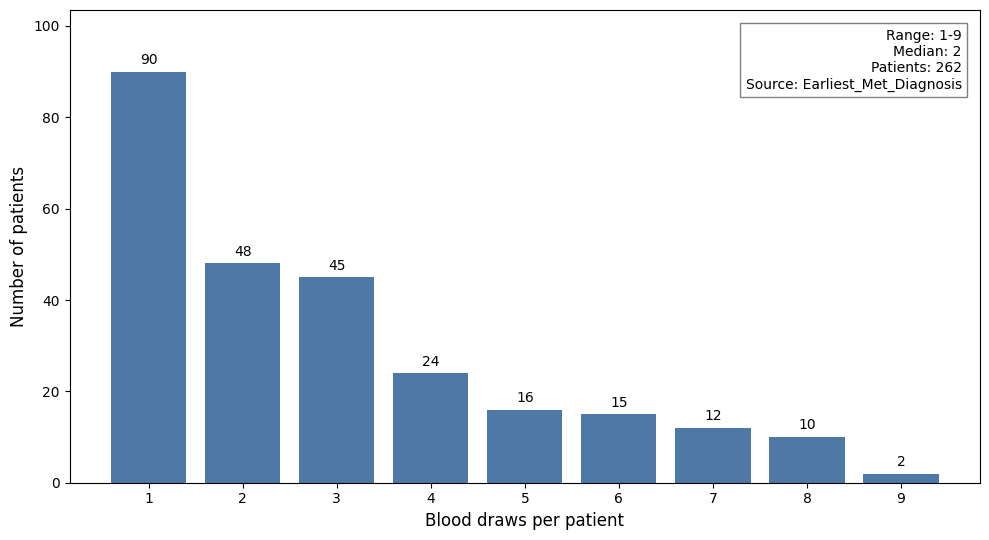


Saved PNG: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/blood_draws_per_patient_distribution.Earliest_Met_Diagnosis.png
Saved PDF: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/blood_draws_per_patient_distribution.Earliest_Met_Diagnosis.pdf

DONE


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# Script purpose:
# Count number of blood draws / samples per patient in the
# AURORA metasheet and plot the distribution.
#
# This script does not directly use ER/PR/HER2 status.
# However, the input metasheet may have receptor information filled
# using either:
#   "First_Primary"
#   "Earliest_Met_Diagnosis"
#
# Set RECEPTOR_SOURCE below to match the metasheet version you want
# to summarize.
# ============================================================

# ============================================================
# Receptor source setting
# ============================================================
# Options:
#   "First_Primary"
#   "Earliest_Met_Diagnosis"
# ============================================================

# RECEPTOR_SOURCE = "First_Primary"
RECEPTOR_SOURCE = "Earliest_Met_Diagnosis"


# ============================================================
# Input file
# ============================================================

clinical_dir = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data"
)

input_file = clinical_dir / (
    f"Metasheet_Analysis.with_Histology_Receptor_status.{RECEPTOR_SOURCE}.xlsx"
)

# If you are still using the older single output file name, use this instead:
# input_file = clinical_dir / "Metasheet_Analysis.with_Histology_Receptor_status.xlsx"


# ============================================================
# Output folder
# ============================================================

out_dir = input_file.parent


# ============================================================
# Load metasheet
# ============================================================

print("Reading metasheet:")
print(input_file)

meta = pd.read_excel(input_file)

print(f"\nMetasheet rows: {meta.shape[0]}")
print(f"Metasheet columns: {meta.shape[1]}")


# ============================================================
# Clean Patient_Identifier column
# ============================================================

patient_col = "Patient_Identifier"

if patient_col not in meta.columns:
    raise ValueError(f"Missing required column: {patient_col}")

meta[patient_col] = (
    meta[patient_col]
    .astype("string")
    .str.strip()
)

# Treat blank / NA-like values as missing
missing_values = ["", "NA", "N/A", "nan", "NaN", "None", "Missing"]
meta.loc[meta[patient_col].isin(missing_values), patient_col] = pd.NA

# Remove rows without Patient_Identifier
meta_clean = meta.dropna(subset=[patient_col]).copy()


# ============================================================
# Count blood draws per patient
# Each row = one blood draw/sample
# ============================================================

blood_draws_per_patient = (
    meta_clean
    .groupby(patient_col)
    .size()
    .reset_index(name="Blood_draw_count")
    .sort_values(["Blood_draw_count", patient_col], ascending=[False, True])
)


# ============================================================
# Distribution:
# How many patients have 1, 2, 3, ... blood draws?
# ============================================================

draw_distribution = (
    blood_draws_per_patient["Blood_draw_count"]
    .value_counts()
    .sort_index()
    .rename_axis("Blood_draws_per_patient")
    .reset_index(name="Number_of_patients")
)


# ============================================================
# Print summaries
# ============================================================

print("\n========== Blood draw summary ==========")
print(f"Receptor source metasheet: {RECEPTOR_SOURCE}")
print(f"Total rows/samples used: {meta_clean.shape[0]}")
print(f"Unique patients: {blood_draws_per_patient[patient_col].nunique()}")
print(
    f"Range: "
    f"{blood_draws_per_patient['Blood_draw_count'].min()}-"
    f"{blood_draws_per_patient['Blood_draw_count'].max()}"
)
print(f"Median: {blood_draws_per_patient['Blood_draw_count'].median():g}")

print("\n========== Distribution ==========")
print(draw_distribution)

print("\n========== Blood draws per patient ==========")
print(blood_draws_per_patient.head(20))


# ============================================================
# Save count tables
# ============================================================

per_patient_file = out_dir / f"blood_draw_count_per_patient.{RECEPTOR_SOURCE}.csv"
distribution_file = out_dir / f"blood_draw_distribution.{RECEPTOR_SOURCE}.csv"

blood_draws_per_patient.to_csv(per_patient_file, index=False)
draw_distribution.to_csv(distribution_file, index=False)

print(f"\nSaved per-patient count table: {per_patient_file}")
print(f"Saved distribution table: {distribution_file}")


# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.bar(
    draw_distribution["Blood_draws_per_patient"],
    draw_distribution["Number_of_patients"],
    color="#4E79A7"
)

# Add count labels above bars
for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        int(height),
        ha="center",
        va="bottom",
        fontsize=10
    )

# Axis labels
ax.set_xlabel("Blood draws per patient", fontsize=12)
ax.set_ylabel("Number of patients", fontsize=12)

# X-axis ticks from minimum to maximum blood draws
min_draws = blood_draws_per_patient["Blood_draw_count"].min()
max_draws = blood_draws_per_patient["Blood_draw_count"].max()
ax.set_xticks(range(min_draws, max_draws + 1))

# Summary box
summary_text = (
    f"Range: {min_draws}-{max_draws}\n"
    f"Median: {blood_draws_per_patient['Blood_draw_count'].median():g}\n"
    f"Patients: {blood_draws_per_patient[patient_col].nunique()}\n"
    f"Source: {RECEPTOR_SOURCE}"
)

ax.text(
    0.98,
    0.96,
    summary_text,
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=10,
    bbox=dict(facecolor="white", edgecolor="gray", boxstyle="square,pad=0.4")
)

ax.set_ylim(0, draw_distribution["Number_of_patients"].max() * 1.15)

plt.tight_layout()


# ============================================================
# Save plot
# ============================================================

png_file = out_dir / f"blood_draws_per_patient_distribution.{RECEPTOR_SOURCE}.png"
pdf_file = out_dir / f"blood_draws_per_patient_distribution.{RECEPTOR_SOURCE}.pdf"

plt.savefig(png_file, dpi=300, bbox_inches="tight", facecolor="white")
plt.savefig(pdf_file, bbox_inches="tight", facecolor="white")

plt.show()

print(f"\nSaved PNG: {png_file}")
print(f"Saved PDF: {pdf_file}")

print("\nDONE")

Reading metasheet:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/Metasheet_Analysis.with_Histology_Receptor_status.Earliest_Met_Diagnosis.xlsx

Metasheet rows: 769
Metasheet columns: 19
Receptor source: Earliest_Met_Diagnosis
Plot level: patient

========== Receptor subtype distribution ==========
Receptor source: Earliest_Met_Diagnosis
Plot level: patient
  Receptor_subtype  Count    Percent
0         HR+HER2-  165.0  62.977099
1         HR+HER2+   19.0   7.251908
2         HR-HER2-   50.0  19.083969
3         HR-HER2+    6.0   2.290076
4          Unknown   22.0   8.396947

Total counted: 262.0

Saved summary table: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/receptor_subtype_distribution_summary.Earliest_Met_Diagnosis.patient.csv


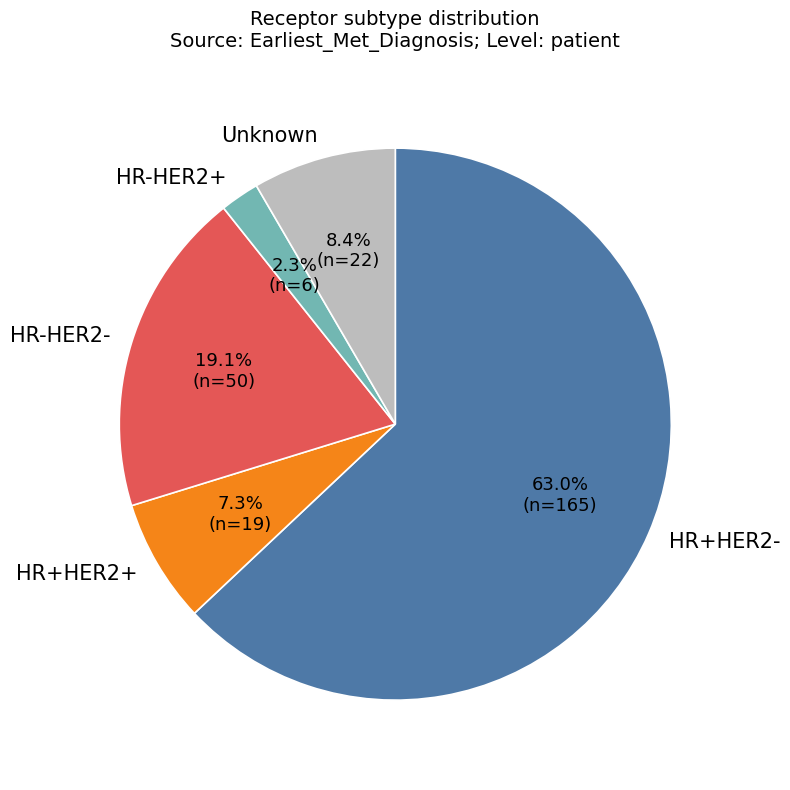


Saved PNG: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/receptor_subtype_distribution_pie.Earliest_Met_Diagnosis.patient.png
Saved PDF: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/receptor_subtype_distribution_pie.Earliest_Met_Diagnosis.patient.pdf

DONE


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# Script purpose:
# Plot receptor / molecular subtype distribution in the AURORA
# metasheet.
#
# The Molecular_subtype column should already be filled in the
# metasheet using either:
#   1. First_Primary receptor information
#   2. Earliest_Met_Diagnosis receptor information
#
# Set RECEPTOR_SOURCE below depending on the question.
# ============================================================

# ============================================================
# Receptor source setting
# ============================================================
# Options:
#   "First_Primary"
#   "Earliest_Met_Diagnosis"
# ============================================================

# RECEPTOR_SOURCE = "First_Primary"
RECEPTOR_SOURCE = "Earliest_Met_Diagnosis"


# ============================================================
# Input file
# ============================================================

clinical_dir = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data"
)

input_file = clinical_dir / (
    f"Metasheet_Analysis.with_Histology_Receptor_status.{RECEPTOR_SOURCE}.xlsx"
)

# If you are still using the older single file name, use this instead:
# input_file = clinical_dir / "Metasheet_Analysis.with_Histology_Receptor_status.xlsx"

out_dir = input_file.parent


# ============================================================
# Settings
# ============================================================

patient_col = "Patient_Identifier"
subtype_col = "Molecular_subtype"

# Use "patient" for unique patient-level plot
# Use "sample" if you want every blood draw/sample counted separately
#
# For manuscript / abstract cohort description, "patient" is safer.
PLOT_LEVEL = "patient"


# ============================================================
# Load file
# ============================================================

print("Reading metasheet:")
print(input_file)

meta = pd.read_excel(input_file)

print(f"\nMetasheet rows: {meta.shape[0]}")
print(f"Metasheet columns: {meta.shape[1]}")
print(f"Receptor source: {RECEPTOR_SOURCE}")
print(f"Plot level: {PLOT_LEVEL}")


# ============================================================
# Check required columns
# ============================================================

required_cols = [patient_col, subtype_col]

for col in required_cols:
    if col not in meta.columns:
        raise ValueError(f"Missing required column in metasheet: {col}")


# ============================================================
# Clean helper
# ============================================================

def clean_text(x):
    if pd.isna(x):
        return pd.NA

    x = str(x).strip()

    if x in ["", "NA", "N/A", "nan", "NaN", "None", "Missing", "missing"]:
        return pd.NA

    return x


def normalize_molecular_subtype(x):
    """
    Normalize molecular subtype names for plotting.

    Expected final labels:
        HR+HER2-
        HR+HER2+
        HR-HER2-
        HR-HER2+
        Unknown
    """

    x = clean_text(x)

    if pd.isna(x):
        return "Unknown"

    s = str(x).upper().replace(" ", "")

    if s in ["UNKNOWN", "MISSING", "NA", "N/A", "NAN", "NONE"]:
        return "Unknown"

    if "TNBC" in s or "TRIPLENEGATIVE" in s:
        return "HR-HER2-"

    if s in ["HR+/HER2-", "HR+HER2-", "HRPOS/HER2NEG"]:
        return "HR+HER2-"

    if s in ["HR+/HER2+", "HR+HER2+", "HRPOS/HER2POS"]:
        return "HR+HER2+"

    if s in ["HR-/HER2-", "HR-HER2-", "HRNEG/HER2NEG"]:
        return "HR-HER2-"

    if s in ["HR-/HER2+", "HR-HER2+", "HRNEG/HER2POS"]:
        return "HR-HER2+"

    return "Unknown"


# ============================================================
# Clean patient and subtype columns
# ============================================================

meta[patient_col] = meta[patient_col].apply(clean_text)
meta[subtype_col] = meta[subtype_col].apply(normalize_molecular_subtype)

# Remove rows without patient identifier
meta_clean = meta.dropna(subset=[patient_col]).copy()


# ============================================================
# Collapse repeated rows per patient
# ============================================================

def collapse_patient_subtype(x):
    """
    Collapse subtype across repeated rows/samples for one patient.

    Logic:
        If only Unknown values exist:
            return Unknown

        If one known subtype plus Unknown:
            return the known subtype

        If the same known subtype appears repeatedly:
            return that subtype

        If multiple different known subtypes appear:
            return Conflicting

    Note:
        If the upstream receptor-filling script worked correctly,
        both First_Primary and Earliest_Met_Diagnosis metasheets should
        usually give one subtype per patient across all blood-draw rows.
    """

    values = pd.Series(x).dropna().astype(str)

    known_values = values[values != "Unknown"].unique()

    if len(known_values) == 0:
        return "Unknown"

    elif len(known_values) == 1:
        return known_values[0]

    else:
        return "Conflicting"


if PLOT_LEVEL == "patient":

    plot_df = (
        meta_clean
        .groupby(patient_col)[subtype_col]
        .apply(collapse_patient_subtype)
        .reset_index(name="Receptor_subtype")
    )

else:

    plot_df = meta_clean[[patient_col, subtype_col]].copy()
    plot_df = plot_df.rename(columns={subtype_col: "Receptor_subtype"})


# ============================================================
# Count receptor subtype distribution
# ============================================================

plot_order = [
    "HR+HER2-",
    "HR+HER2+",
    "HR-HER2-",
    "HR-HER2+",
    "Unknown",
    "Conflicting"
]

counts = (
    plot_df["Receptor_subtype"]
    .value_counts()
    .reindex(plot_order)
    .dropna()
)

counts = counts[counts > 0]

summary_df = counts.reset_index()
summary_df.columns = ["Receptor_subtype", "Count"]
summary_df["Percent"] = summary_df["Count"] / summary_df["Count"].sum() * 100

print("\n========== Receptor subtype distribution ==========")
print(f"Receptor source: {RECEPTOR_SOURCE}")
print(f"Plot level: {PLOT_LEVEL}")
print(summary_df)

print("\nTotal counted:", counts.sum())


# ============================================================
# Print conflicting cases if any
# ============================================================

if "Conflicting" in counts.index:

    conflicting_cases = plot_df.loc[
        plot_df["Receptor_subtype"] == "Conflicting",
        patient_col
    ]

    print("\n========== Conflicting patients ==========")
    print(conflicting_cases.to_string(index=False))


# ============================================================
# Save summary table
# ============================================================

summary_file = out_dir / (
    f"receptor_subtype_distribution_summary."
    f"{RECEPTOR_SOURCE}.{PLOT_LEVEL}.csv"
)

summary_df.to_csv(summary_file, index=False)

print(f"\nSaved summary table: {summary_file}")


# ============================================================
# Pie chart
# ============================================================

def autopct_format(values):
    total = sum(values)

    def inner_autopct(pct):
        count = int(round(pct * total / 100.0))
        return f"{pct:.1f}%\n(n={count})"

    return inner_autopct


color_map = {
    "HR+HER2-": "#4E79A7",
    "HR+HER2+": "#F58518",
    "HR-HER2-": "#E45756",
    "HR-HER2+": "#72B7B2",
    "Unknown": "#BDBDBD",
    "Conflicting": "#7F7F7F"
}

colors = [color_map[x] for x in counts.index]

fig, ax = plt.subplots(figsize=(8, 8))

wedges, texts, autotexts = ax.pie(
    counts.values,
    labels=counts.index,
    colors=colors,
    autopct=autopct_format(counts.values),
    startangle=90,
    counterclock=False,
    labeldistance=1.08,
    pctdistance=0.65,
    wedgeprops=dict(edgecolor="white", linewidth=1.2),
    textprops=dict(fontsize=15)
)

# Style percentage text
for autotext in autotexts:
    autotext.set_fontsize(13)
    autotext.set_color("black")

ax.axis("equal")

title_text = (
    f"Receptor subtype distribution\n"
    f"Source: {RECEPTOR_SOURCE}; Level: {PLOT_LEVEL}"
)

ax.set_title(title_text, fontsize=14, pad=18)

plt.tight_layout()


# ============================================================
# Save plot
# ============================================================

png_file = out_dir / (
    f"receptor_subtype_distribution_pie."
    f"{RECEPTOR_SOURCE}.{PLOT_LEVEL}.png"
)

pdf_file = out_dir / (
    f"receptor_subtype_distribution_pie."
    f"{RECEPTOR_SOURCE}.{PLOT_LEVEL}.pdf"
)

plt.savefig(png_file, dpi=300, bbox_inches="tight", facecolor="white")
plt.savefig(pdf_file, bbox_inches="tight", facecolor="white")

plt.show()

print(f"\nSaved PNG: {png_file}")
print(f"Saved PDF: {pdf_file}")

print("\nDONE")


========== Histology distribution ==========
  Histological_subtype  Count    Percent
0               Ductal  210.0  80.152672
1              Lobular   25.0   9.541985
2                Mixed   21.0   8.015267
3              Unknown    6.0   2.290076

Total counted: 262.0


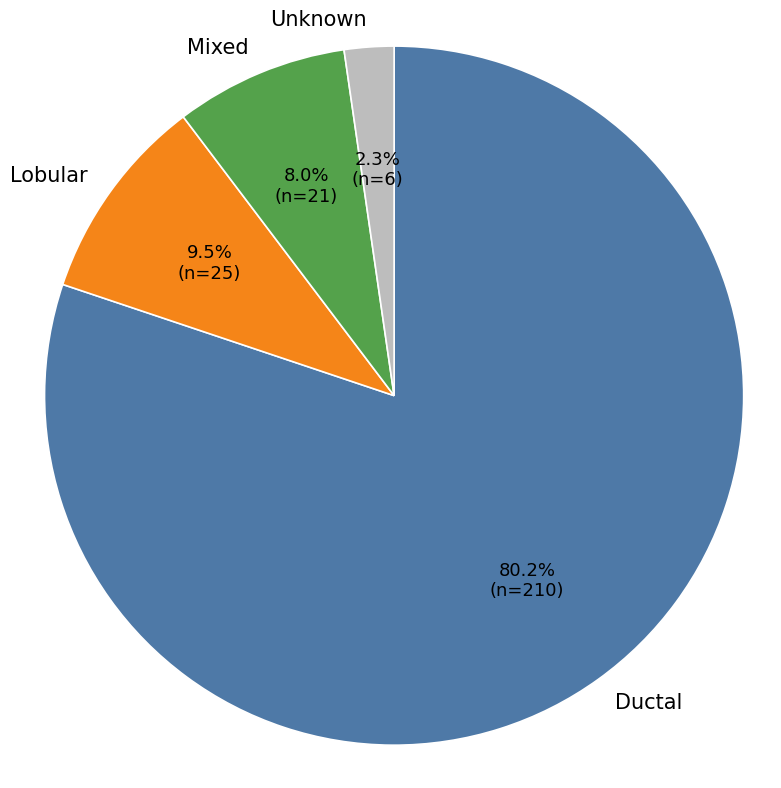

Saved PNG: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/histology_distribution_pie.png
Saved PDF: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/histology_distribution_pie.pdf


Reading metasheet:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/Metasheet_Analysis.with_Histology_Receptor_status.First_Primary.xlsx

Metasheet rows: 769
Metasheet columns: 19
Clinical source: First_Primary
Plot level: patient

========== Histology distribution ==========
Clinical source: First_Primary
Plot level: patient
  Histological_subtype  Count    Percent
0               Ductal  210.0  80.152672
1              Lobular   25.0   9.541985
2                Mixed   21.0   8.015267
3              Unknown    6.0   2.290076

Total counted: 262.0

Saved summary table: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/histology_distribution_summary.First_Primary.patient.csv


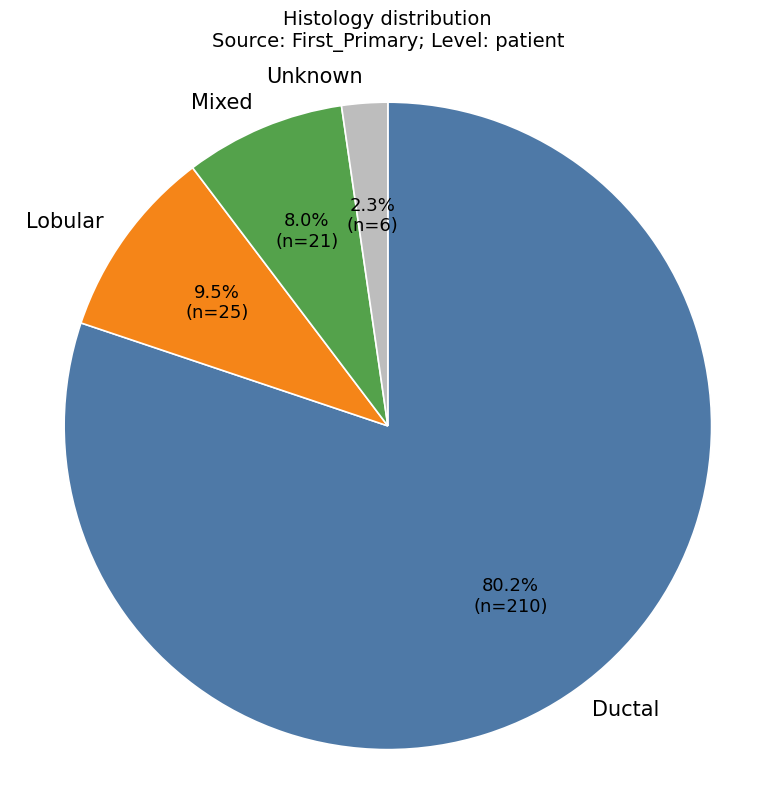


Saved PNG: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/histology_distribution_pie.First_Primary.patient.png
Saved PDF: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/histology_distribution_pie.First_Primary.patient.pdf

DONE


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# Script purpose:
# Plot histological subtype distribution in the AURORA metasheet.
#
# The Histological_subtype column should already be filled in the
# metasheet using either:
#   1. First_Primary clinical information
#   2. Earliest_Met_Diagnosis clinical information
#
# Set RECEPTOR_SOURCE below depending on the question.
#
# Note:
#   Even though the variable is called RECEPTOR_SOURCE for consistency
#   with the receptor subtype scripts, this setting also controls the
#   source of Histological_subtype because histology was filled from the
#   same clinical source in the upstream metasheet-generation script.
# ============================================================

# ============================================================
# Clinical source setting
# ============================================================
# Options:
#   "First_Primary"
#   "Earliest_Met_Diagnosis"
# ============================================================
RECEPTOR_SOURCE = "First_Primary"
# RECEPTOR_SOURCE = "Earliest_Met_Diagnosis"


# ============================================================
# Input file
# ============================================================

clinical_dir = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data"
)

input_file = clinical_dir / (
    f"Metasheet_Analysis.with_Histology_Receptor_status.{RECEPTOR_SOURCE}.xlsx"
)

# If you are still using the older single file name, use this instead:
# input_file = clinical_dir / "Metasheet_Analysis.with_Histology_Receptor_status.xlsx"

out_dir = input_file.parent


# ============================================================
# Settings
# ============================================================

patient_col = "Patient_Identifier"
histology_col = "Histological_subtype"

# Use "patient" for unique patient-level plot
# Use "sample" if you want every blood draw/sample counted separately
#
# For manuscript / abstract cohort description, "patient" is safer.
PLOT_LEVEL = "patient"


# ============================================================
# Load file
# ============================================================

print("Reading metasheet:")
print(input_file)

meta = pd.read_excel(input_file)

print(f"\nMetasheet rows: {meta.shape[0]}")
print(f"Metasheet columns: {meta.shape[1]}")
print(f"Clinical source: {RECEPTOR_SOURCE}")
print(f"Plot level: {PLOT_LEVEL}")


# ============================================================
# Check required columns
# ============================================================

required_cols = [patient_col, histology_col]

for col in required_cols:
    if col not in meta.columns:
        raise ValueError(f"Missing required column in metasheet: {col}")


# ============================================================
# Clean helper
# ============================================================

def clean_text(x):
    if pd.isna(x):
        return pd.NA

    x = str(x).strip()

    if x in ["", "NA", "N/A", "nan", "NaN", "None", "Missing", "missing"]:
        return pd.NA

    return x


def normalize_histology(x):
    """
    Normalize histology subtype names for plotting.

    Expected final labels:
        Ductal
        Lobular
        Mixed
        Unknown
    """

    x = clean_text(x)

    if pd.isna(x):
        return "Unknown"

    s = str(x).strip().lower()

    if s in ["unknown", "missing", "na", "n/a", "nan", "none"]:
        return "Unknown"

    if "mixed" in s and "lobular" in s:
        return "Mixed"

    if "ductal" in s and "lobular" in s:
        return "Mixed"

    if "lobular" in s:
        return "Lobular"

    if "ductal" in s:
        return "Ductal"

    return "Unknown"


# ============================================================
# Clean patient and histology columns
# ============================================================

meta[patient_col] = meta[patient_col].apply(clean_text)
meta[histology_col] = meta[histology_col].apply(normalize_histology)

# Remove rows without patient identifier
meta_clean = meta.dropna(subset=[patient_col]).copy()


# ============================================================
# Collapse repeated rows per patient
# ============================================================

def collapse_patient_histology(x):
    """
    Collapse histology across repeated rows/samples for one patient.

    Logic:
        If only Unknown values exist:
            return Unknown

        If one known histology plus Unknown:
            return the known histology

        If the same known histology appears repeatedly:
            return that histology

        If multiple different known histologies appear:
            return Conflicting

    Note:
        If the upstream metasheet-generation script worked correctly,
        each patient should usually have one histology assignment across
        all blood-draw rows.
    """

    values = pd.Series(x).dropna().astype(str)

    known_values = values[values != "Unknown"].unique()

    if len(known_values) == 0:
        return "Unknown"

    elif len(known_values) == 1:
        return known_values[0]

    else:
        return "Conflicting"


if PLOT_LEVEL == "patient":

    plot_df = (
        meta_clean
        .groupby(patient_col)[histology_col]
        .apply(collapse_patient_histology)
        .reset_index(name="Histological_subtype")
    )

else:

    plot_df = meta_clean[[patient_col, histology_col]].copy()
    plot_df = plot_df.rename(columns={histology_col: "Histological_subtype"})


# ============================================================
# Count histology distribution
# ============================================================

plot_order = [
    "Ductal",
    "Lobular",
    "Mixed",
    "Unknown",
    "Conflicting"
]

counts = (
    plot_df["Histological_subtype"]
    .value_counts()
    .reindex(plot_order)
    .dropna()
)

counts = counts[counts > 0]

summary_df = counts.reset_index()
summary_df.columns = ["Histological_subtype", "Count"]
summary_df["Percent"] = summary_df["Count"] / summary_df["Count"].sum() * 100

print("\n========== Histology distribution ==========")
print(f"Clinical source: {RECEPTOR_SOURCE}")
print(f"Plot level: {PLOT_LEVEL}")
print(summary_df)

print("\nTotal counted:", counts.sum())


# ============================================================
# Print conflicting patients if any
# ============================================================

if "Conflicting" in counts.index:

    conflicting_cases = plot_df.loc[
        plot_df["Histological_subtype"] == "Conflicting",
        patient_col
    ]

    print("\n========== Conflicting patients ==========")
    print(conflicting_cases.to_string(index=False))


# ============================================================
# Save summary table
# ============================================================

summary_file = out_dir / (
    f"histology_distribution_summary."
    f"{RECEPTOR_SOURCE}.{PLOT_LEVEL}.csv"
)

summary_df.to_csv(summary_file, index=False)

print(f"\nSaved summary table: {summary_file}")


# ============================================================
# Pie chart
# ============================================================

def autopct_format(values):
    total = sum(values)

    def inner_autopct(pct):
        count = int(round(pct * total / 100.0))
        return f"{pct:.1f}%\n(n={count})"

    return inner_autopct


color_map = {
    "Ductal": "#4E79A7",
    "Lobular": "#F58518",
    "Mixed": "#54A24B",
    "Unknown": "#BDBDBD",
    "Conflicting": "#7F7F7F"
}

colors = [color_map[x] for x in counts.index]

fig, ax = plt.subplots(figsize=(8, 8))

wedges, texts, autotexts = ax.pie(
    counts.values,
    labels=counts.index,
    colors=colors,
    autopct=autopct_format(counts.values),
    startangle=90,
    counterclock=False,
    labeldistance=1.08,
    pctdistance=0.65,
    wedgeprops=dict(edgecolor="white", linewidth=1.2),
    textprops=dict(fontsize=15)
)

for autotext in autotexts:
    autotext.set_fontsize(13)
    autotext.set_color("black")

ax.axis("equal")

title_text = (
    f"Histology distribution\n"
    f"Source: {RECEPTOR_SOURCE}; Level: {PLOT_LEVEL}"
)

ax.set_title(title_text, fontsize=14, pad=18)

plt.tight_layout()


# ============================================================
# Save plot
# ============================================================

png_file = out_dir / (
    f"histology_distribution_pie."
    f"{RECEPTOR_SOURCE}.{PLOT_LEVEL}.png"
)

pdf_file = out_dir / (
    f"histology_distribution_pie."
    f"{RECEPTOR_SOURCE}.{PLOT_LEVEL}.pdf"
)

plt.savefig(png_file, dpi=300, bbox_inches="tight", facecolor="white")
plt.savefig(pdf_file, bbox_inches="tight", facecolor="white")

plt.show()

print(f"\nSaved PNG: {png_file}")
print(f"Saved PDF: {pdf_file}")

print("\nDONE")